# Multilayer Perceptrons: Classification and Regression

<a href="https://colab.research.google.com/github/rubenfonnegra/machine_learning/blob/master/Sem_11/MLP_Classification_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a> 
<a href="https://github.com/rubenfonnegra/machine_learning/blob/master/Sem_11/MLP_Classification_Regression.ipynb" target="_parent"><img src="https://img.shields.io/badge/%E2%80%8B-Open%20in%20Github-blue?logo=github" alt="Open In Github"/></a> 

This notebook extends our single layer perceptron lesson to two real datasets: **fruit classification** and **Iowa house-price regression**. Each section includes an experiment comparing hidden-layer activation functions.

### Learning objectives
- Understand how multilayer neural networks overcome the limitations of a single perceptron.
- Identify the architecture and main components of a Multilayer Perceptron (MLP).
- Explain how information flows through multiple neural network layers.
- Understand the basic principles of forward propagation and backpropagation.
- Recognize the importance of activation functions and optimization in neural network training.
- Understand how Convolutional Neural Networks (CNNs) process images.
- Identify the main components of CNN architectures: convolutional layers, filters, pooling, and fully connected layers.
- Implement basic MLP and CNN models using Python and Deep Learning libraries.


### Documentation

- [```PyTorch```](https://pytorch.org/) 
- [```PyTorch Documentation```](https://docs.pytorch.org/docs/2.14/index.html)
- [```Keras```](https://keras.io/)

---

> **📘 Machine Learning**  
> **Author:** Rubén D. Fonnegra, Ph.D. \
> **Institution:** Institución Universitaria Pascual Bravo  
> © 2026 · Educational use with attribution


## Environment

Set the backend **before** importing Keras. Restart the kernel if Keras was previously imported with another backend.

In [4]:
import os
os.environ["KERAS_BACKEND"] = "torch"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import accuracy_score, confusion_matrix, mean_squared_error, mean_absolute_error, r2_score

import keras 
print("Keras:", keras.__version__, "| Backend:", keras.backend.backend())

Keras: 3.3.2 | Backend: torch


## What changes between classification and regression?

An MLP applies a sequence of learned transformations:

$$h_1=g(XW_1+b_1),\qquad h_2=g(h_1W_2+b_2),\qquad \hat y=f(h_2W_3+b_3).$$

The **hidden activation** $g$ can be ReLU, tanh, sigmoid, or linear. The **output activation** $f$ depends on the problem.

| | Fruit classification | House-price regression |
|---|---|---|
| Output | Softmax class probabilities | Linear numeric prediction |
| Loss | Categorical cross-entropy | Mean squared error |
| Evaluation | Accuracy, confusion matrix | RMSE, MAE, R² |

For a fair comparison, we change **hidden activations only**.


# Classification

## Load and inspect the dataset

In [ ]:
CSV_PATH = _ 
fruits = pd.read_csv(CSV_PATH)

display(fruits.head())


,fruit_label,fruit_name,fruit_subtype,mass,width,height,color_score
0,1,apple,granny_smith,192.0,8.4,7.3,0.55
1,1,apple,granny_smith,180.0,8.0,6.8,0.59
2,1,apple,granny_smith,176.0,7.4,7.2,0.60
3,2,mandarin,mandarin,86.0,6.2,4.7,0.80
4,2,mandarin,mandarin,84.0,6.0,4.6,0.79


mandarin    106
orange      103
lemon        99
grapes       99
apple        91
Name: fruit_name, dtype: int64


## Visualize the fruit features

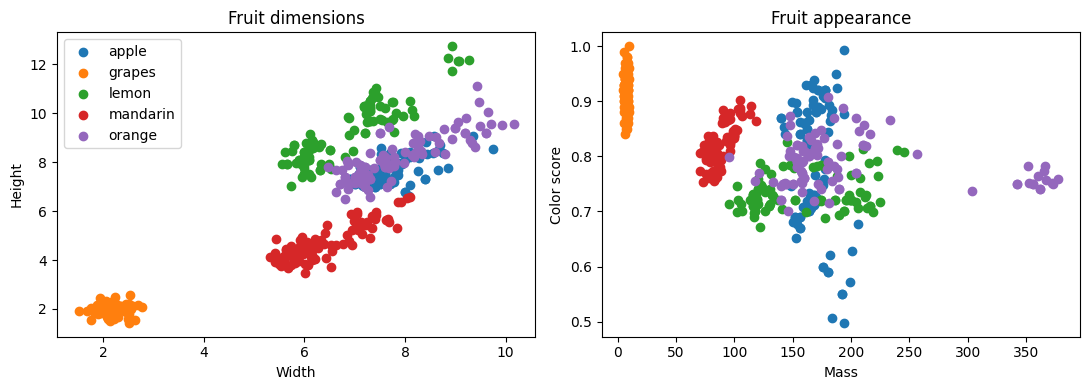

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, group in fruits.groupby("fruit_name"):
    axes[0].scatter(group["width"], group["height"], label=name)
    axes[1].scatter(group["mass"], group["color_score"], label=name)

axes[0].set(xlabel="Width", ylabel="Height", title="Fruit dimensions")
axes[1].set(xlabel="Mass", ylabel="Color score", title="Fruit appearance")
axes[0].legend()
plt.tight_layout()
plt.show()


## Holdout

In [ ]:
fruit_features = ["mass", "width", "height", "color_score"]

X_fruit = fruits[fruit_features].to_numpy(dtype="float32")
y_fruit = fruits["fruit_label"]

encoder = OneHotEncoder(sparse_output=False)
y_fruit_oh = encoder.fit_transform(y_fruit.values.reshape(-1, 1))

Xf_train, Xf_test, yf_train, yf_test = train_test_split(X_fruit, y_fruit_oh, test_size=0.2, random_state=42)

fruit_scaler = StandardScaler()
Xf_train = fruit_scaler.fit_transform(Xf_train)
Xf_test = fruit_scaler.transform(Xf_test)

print("Classes:", np.unique(y_fruit), "| Train:", Xf_train.shape, "| Test:", Xf_test.shape)

Classes: [1 2 3 4 5] | Train: (373, 4) | Test: (125, 4)


## Define the classification MLP

Two hidden layers learn nonlinear feature combinations; the final softmax layer estimates class probabilities.

In [ ]:
def build_classifier(activation="relu"):
    model = keras.Sequential([
        keras.Input(shape= (len(fruit_features),) ),
        keras.layers.Dense( _ , activation=activation),
        keras.layers.Dense( _ , activation=activation),
        keras.layers.Dense( len(np.unique(y_fruit) ), activation="softmax")
    ])
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01),
                  loss="categorical_crossentropy", metrics=["accuracy"])
    return model

keras.utils.set_random_seed(42)
fruit_model = build_classifier()
fruit_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 773 (3.02 KB)

 Trainable params: 773 (3.02 KB)

 Non-trainable params: 0 (0.00 B)

## Train and evaluate the classifier

In [ ]:
fruit_history = fruit_model.fit( _ ,  _ , 
                                validation_split = 0.2, epochs = 150, 
                                batch_size = _ , verbose = 1)

Epoch 1/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4062 - loss: 1.4321 - val_accuracy: 0.6000 - val_loss: 1.0871
Epoch 2/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7198 - loss: 0.8811 - val_accuracy: 0.8133 - val_loss: 0.6843
Epoch 3/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8653 - loss: 0.5418 - val_accuracy: 0.8000 - val_loss: 0.4872
Epoch 4/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8586 - loss: 0.4321 - val_accuracy: 0.8133 - val_loss: 0.3778
Epoch 5/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8949 - loss: 0.2511 - val_accuracy: 0.9200 - val_loss: 0.2692
Epoch 6/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9187 - loss: 0.2249 - val_accuracy: 0.9067 - val_loss: 0.2265
Epoch 7/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9093 - loss: 0.2346 - val_accuracy: 0.9067 - val_loss: 0.2236
Epoch 8/150
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9543 - loss: 0.1681 - val_accuracy: 0.8933 - v

Test accuracy: 0.952


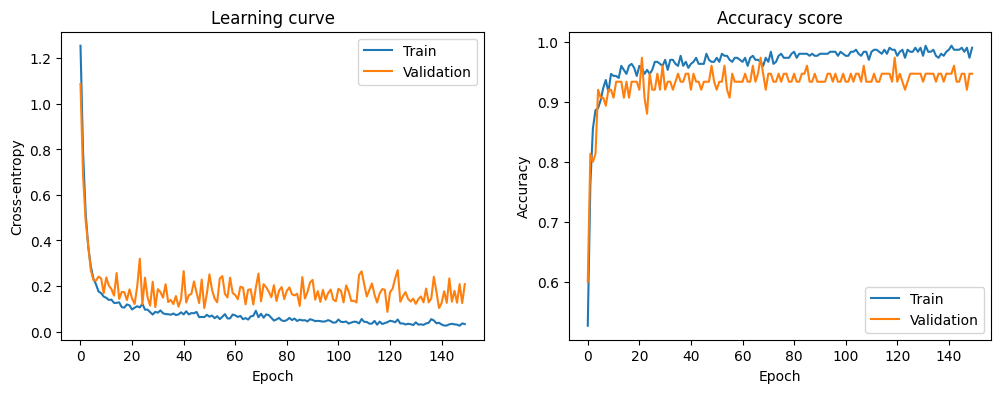

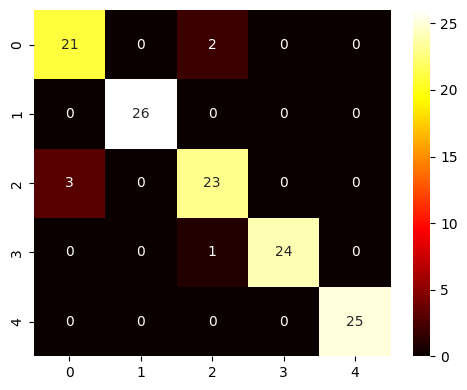

In [ ]:
fruit_predictions = fruit_model.predict( _ , verbose=0)
fruit_predictions = np.argmax(fruit_predictions, axis=1)

yf_test_ = np.argmax(yf_test, axis=1)

print("Test accuracy:", round(accuracy_score(yf_test_, fruit_predictions), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fruit_history.history["loss"], label="Train")
axes[0].plot(fruit_history.history["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="Cross-entropy", title="Learning curve")
axes[0].legend()

axes[1].plot(fruit_history.history["accuracy"], label="Train")
axes[1].plot(fruit_history.history["val_accuracy"], label="Validation")
axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy score")
axes[1].legend()

cm = confusion_matrix(yf_test_, fruit_predictions)

_, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, cmap='hot', ax = ax)
plt.tight_layout()
plt.show()


## Does the activation function matter?

Compare **ReLU, tanh, sigmoid, and linear** in the hidden layers. Keep the architecture, split, optimizer, and epochs fixed. A linear hidden activation removes the network's nonlinear transformations.

In [ ]:
fruit_results, fruit_histories = [], {}

for activation in ["relu", "tanh", "sigmoid", "linear"]:
    keras.utils.set_random_seed(42)
    candidate = build_classifier(activation)
    history = candidate.fit( _ , _ , validation_split=0.2, epochs=150, batch_size=10, verbose=0)
    loss, accuracy = candidate.evaluate(Xf_test, yf_test, verbose=0)
    fruit_results.append({"Activation": activation, "Test accuracy": accuracy, "Test loss": loss})
    fruit_histories[activation] = history.history

,Activation,Test accuracy,Test loss
0,relu,0.960,0.143851
1,tanh,0.944,0.209620
2,sigmoid,0.944,0.165152
3,linear,0.872,0.254061


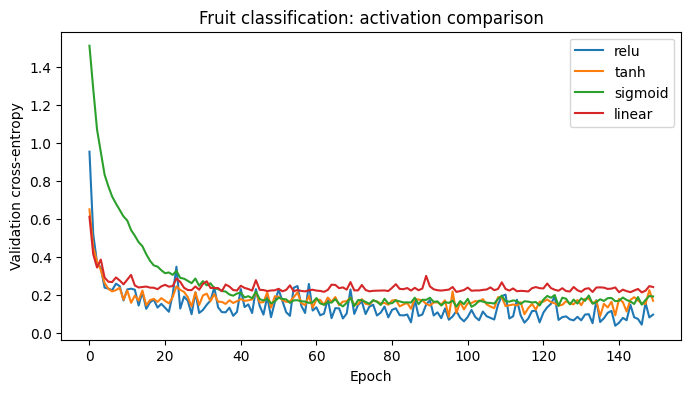

In [ ]:
display(pd.DataFrame(fruit_results).sort_values("Test accuracy", ascending=False))

plt.figure(figsize=(8, 4))
for activation, history in fruit_histories.items():
    plt.plot(history["val_loss"], label=activation)
plt.xlabel("Epoch")
plt.ylabel("Validation cross-entropy")
plt.title("Fruit classification: activation comparison")
plt.legend()
plt.show()

# Regression

## Load and inspect the dataset


In [ ]:
house_path = _ 
houses = pd.read_csv(house_path)

house_features = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "FullBath", "YearBuilt", "1stFlrSF", "LotArea"]
required = house_features + ["SalePrice"]

display(houses[required].head())
print("Observations:", len(houses))


,OverallQual,GrLivArea,GarageCars,TotalBsmtSF,FullBath,YearBuilt,1stFlrSF,LotArea,SalePrice
0,7,1710,2,856,2,2003,856,8450,208500
1,6,1262,2,1262,2,1976,1262,9600,181500
2,7,1786,2,920,2,2001,920,11250,223500
3,7,1717,3,756,1,1915,961,9550,140000
4,8,2198,3,1145,2,2000,1145,14260,250000


Observations: 1338


## Explore and transform the target

House prices are right-skewed. We train on **standardized log-prices** to improve numerical stability, then convert predictions back to dollars for evaluation:

$$z=\frac{\log(1+\mathrm{SalePrice})-\mu}{\sigma}.$$

The reported RMSE and MAE are calculated in **dollars**, not log units.


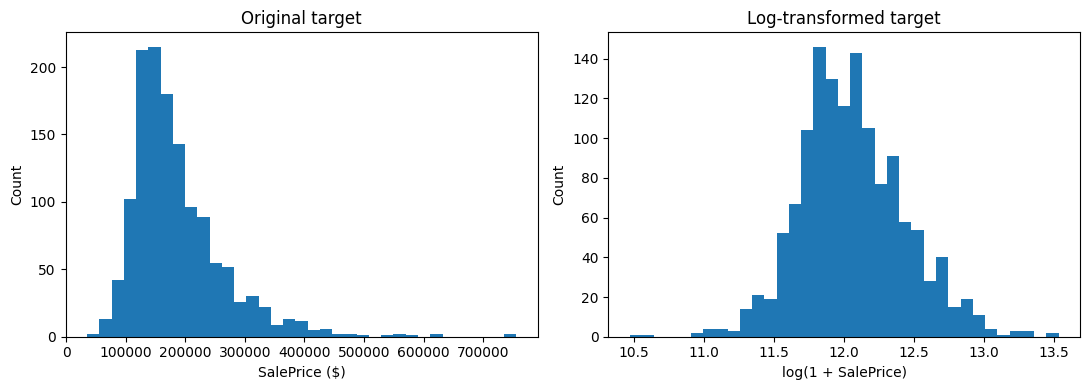

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(houses["SalePrice"], bins=35)
axes[0].set(xlabel="SalePrice ($)", ylabel="Count", title="Original target")
axes[1].hist(np.log1p(houses["SalePrice"]), bins=35)
axes[1].set(xlabel="log(1 + SalePrice)", ylabel="Count", title="Log-transformed target")
plt.tight_layout()
plt.show()


## Holdout

In [19]:
X_house = houses[house_features]
y_house = houses["SalePrice"].to_numpy(dtype="float64")

Xh_train_raw, Xh_test_raw, yh_train_raw, yh_test_raw = train_test_split(X_house, y_house, test_size=0.2, random_state=42)

house_imputer, house_scaler = SimpleImputer(strategy="median"), StandardScaler()
Xh_train = house_scaler.fit_transform(house_imputer.fit_transform(Xh_train_raw)).astype("float32")
Xh_test = house_scaler.transform(house_imputer.transform(Xh_test_raw)).astype("float32")

log_train = np.log1p(yh_train_raw)
target_mean, target_std = log_train.mean(), log_train.std()
yh_train = ((log_train - target_mean) / target_std).astype("float32")
yh_test = ((np.log1p(yh_test_raw) - target_mean) / target_std).astype("float32")

print("Train:", Xh_train.shape, "| Test:", Xh_test.shape)


Train: (1070, 8) | Test: (268, 8)


## Define the regression MLP

Use a **linear output** and MSE. Softmax and sigmoid would inappropriately constrain the continuous regression output.

In [ ]:
def build_regressor(activation="relu"):
    model = keras.Sequential([
        keras.Input(shape=(len(house_features),)),
        keras.layers.Dense( _ , activation=activation),
        keras.layers.Dense( _ , activation=activation),
        keras.layers.Dense( _ )
    ])
    model.compile(optimizer=keras.optimizers.SGD(learning_rate=0.01), loss="mse", metrics=["mae"])
    return model

def inverse_target(predictions):
    return np.expm1(np.asarray(predictions).reshape(-1) * target_std + target_mean)

keras.utils.set_random_seed(42)
house_model = build_regressor()
house_model.summary()


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

## Train and evaluate the regressor

Early stopping monitors validation MSE; the test set remains reserved for final evaluation.

In [ ]:
house_history = house_model.fit( _ , _ , 
                                validation_split=0.2, epochs=250, 
                                batch_size=32, verbose=1)

Epoch 1/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0981 - mae: 0.2219 - val_loss: 0.1448 - val_mae: 0.2874
Epoch 2/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1021 - mae: 0.2203 - val_loss: 0.1529 - val_mae: 0.2870
Epoch 3/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1046 - mae: 0.2297 - val_loss: 0.1387 - val_mae: 0.2809
Epoch 4/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0857 - mae: 0.2141 - val_loss: 0.1470 - val_mae: 0.2866
Epoch 5/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0814 - mae: 0.2112 - val_loss: 0.1496 - val_mae: 0.2842
Epoch 6/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0913 - mae: 0.2233 - val_loss: 0.1447 - val_mae: 0.2845
Epoch 7/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0907 - mae: 0.2169 - val_loss: 0.1455 - val_mae: 0.2847
Epoch 8/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0839 - mae: 0.2132 - val_loss: 0.1465 - val_mae: 0.2839
Epoch 9/250
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.085

In [ ]:
house_predictions = house_model.predict(Xh_test, verbose=0) 
house_predictions = inverse_target()

house_mse = mean_squared_error(yh_test_raw, house_predictions)
house_mae = mean_absolute_error(yh_test_raw, house_predictions)
house_r2 = r2_score(yh_test_raw, house_predictions)
print(f"Test MSE: ${house_mse:,.0f} | MAE: ${house_mae:,.0f} | R²: {house_r2:.3f}")

Test RMSE: $32,912 | MAE: $21,734 | R²: 0.747


## Visualize house-price predictions

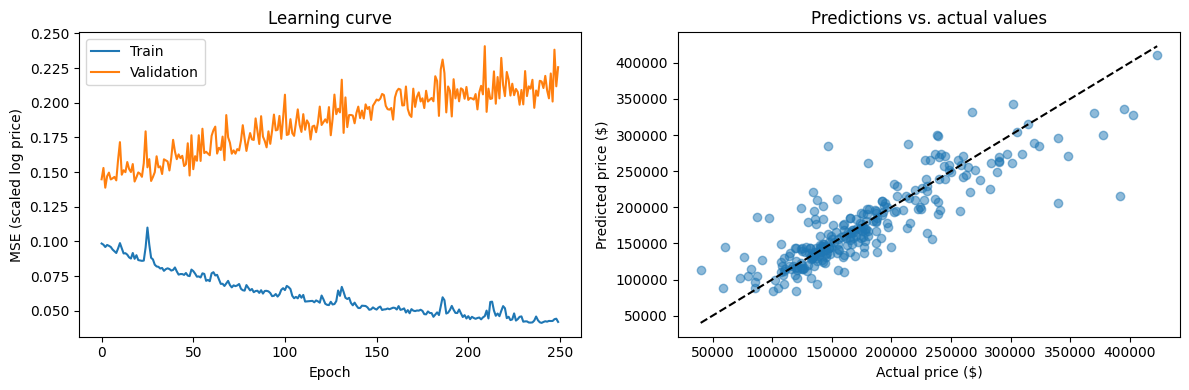

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(house_history.history["loss"], label="Train")
axes[0].plot(house_history.history["val_loss"], label="Validation")
axes[0].set(xlabel="Epoch", ylabel="MSE (scaled log price)", title="Learning curve")
axes[0].legend()

axes[1].scatter(yh_test_raw, house_predictions, alpha=0.5)
limits = [min(yh_test_raw.min(), house_predictions.min()), max(yh_test_raw.max(), house_predictions.max())]
axes[1].plot(limits, limits, "--", color="black")
axes[1].set(xlabel="Actual price ($)", ylabel="Predicted price ($)", title="Predictions vs. actual values")

plt.tight_layout()
plt.show()


## Does the activation function matter for regression?

Compare the same four hidden activations. **Lower RMSE and MAE** indicate better dollar-scale prediction; **higher R²** is better. Each candidate has its own early-stopping callback.


In [ ]:
house_results, house_histories = [], {}

for activation in ["relu", "tanh", "sigmoid", "linear"]:
    keras.utils.set_random_seed(42)
    candidate = build_regressor(activation)
    history = candidate.fit( _ , _ , validation_split=0.2, epochs=250, batch_size=32, verbose=0)
    predictions = inverse_target(candidate.predict(Xh_test, verbose=0))
    house_results.append({"Activation": activation, "MSE ($)": mean_squared_error(yh_test_raw, predictions),
                          "MAE ($)": mean_absolute_error(yh_test_raw, predictions), "R²": r2_score(yh_test_raw, predictions),
                          "Epochs": len(history.history["loss"])})
    house_histories[activation] = history.history

,Activation,RMSE ($),MAE ($),R²,Epochs
2,sigmoid,28790.798434,20647.931874,0.806289,250
3,linear,29619.170510,20959.689453,0.794982,250
0,relu,31922.117669,21223.968808,0.761861,250
1,tanh,32326.145975,21768.686451,0.755795,250


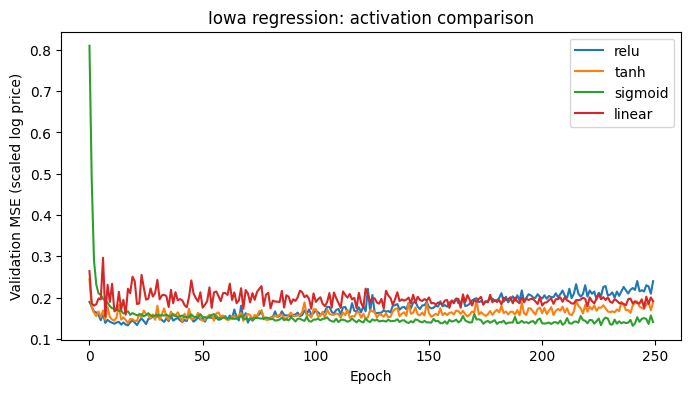

In [26]:
display(pd.DataFrame(house_results).sort_values("RMSE ($)"))
plt.figure(figsize=(8, 4))
for activation, history in house_histories.items():
    plt.plot(history["val_loss"], label=activation)
plt.xlabel("Epoch")
plt.ylabel("Validation MSE (scaled log price)")
plt.title("Iowa regression: activation comparison")
plt.legend()
plt.show()

# Challenges

- Repeat the experiments with hidden sizes `(8, 4)` and `(128, 64)`. Does a larger network always generalize better?
- Replace ReLU with `elu` and compare training curves.
- Explain the purpose of the training, validation, and test partitions.
- Repeat the activation experiments with three random seeds and compare mean and standard deviation of test metrics.

In [ ]:
## Add your code here 


---

## 📄 Attribution

This notebook was developed by **Rubén D. Fonnegra** as educational material for Machine Learning courses at **Institución Universitaria Pascual Bravo**.
You may use, share, and adapt this material for educational purposes, provided that appropriate credit is given to the original author.

**Suggested citation:**
> Fonnegra Tarazona, R. D. (2026). *Neural Networks - Multilayer Perceptron (classification and regression): Machine Learning Notebook*. Institución Universitaria Pascual Bravo.